# Page-level HTR pipeline

Validation page -> RF-DETR Small (score >= 0.55) -> handwritten crops -> TrOCR baseline -> lines joined top to bottom. Page CER compares this text with the page's eligible ground-truth lines in the same order. Missed lines count as deletions and extra predictions as insertions, so it is stricter than the matched-line CER in notebook 08. Reading order only suits single-column pages.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
from PIL import Image
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
from transformers.utils import logging

sys.path.insert(0, '../src')
from cv import pages_with_split, subset
from htr import ROOT, cer_interval, snapshot
from pipeline import THRESHOLD, detect, page_errors, reference_lines, transcribe

logging.set_verbosity_error()
logging.disable_progress_bar()
pd.set_option('display.max_colwidth', 100)

DETECTOR_DIR = ROOT / 'models/rf-small-refined/best'
MODEL_DIR = ROOT / 'models/trocr-uk-baseline'
RESULTS_DIR = ROOT / 'results/htr'
DECODING = dict(num_beams=4, no_repeat_ngram_size=0, max_length=130)

val = subset(pages_with_split(), 'val')
len(val)

/home/stalex/unik_shit/ai/pandemonium-rukopys/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


133

In [2]:
start = time.time()
detections = detect(val, DETECTOR_DIR)
print(f'detection: {time.time() - start:.0f} s')

processor = TrOCRProcessor.from_pretrained(MODEL_DIR)
model = VisionEncoderDecoderModel.from_pretrained(MODEL_DIR).cuda()
start = time.time()
regions = {p['file_name']: transcribe(p, detections[p['file_name']], model, processor, **DECODING) for p in val}
print(f'recognition: {time.time() - start:.0f} s')

Validation: 25/133 pages


Validation: 50/133 pages


Validation: 75/133 pages


Validation: 100/133 pages


Validation: 125/133 pages


detection: 43 s


recognition: 345 s


In [3]:
rows = []
for p in val:
    ref = ' '.join(reference_lines(p))
    lines = [r['text'] for r in regions[p['file_name']] if r['text']]
    hyp = ' '.join(lines)
    rows.append(dict(page_id=Path(p['file_name']).stem, source=p['source'], ref_lines=len(reference_lines(p)),
                     pred_lines=len(lines), chars=len(ref), char_errors=page_errors(ref, hyp),
                     reference=ref, prediction=hyp))
pages = pd.DataFrame(rows)


def summary(group):
    low, high = cer_interval(group)
    return pd.Series(dict(pages=len(group), CER=group.char_errors.sum() / group.chars.sum(),
                          CER_95_low=low, CER_95_high=high))


table = pd.concat([pages.groupby('source').apply(summary, include_groups=False), summary(pages).to_frame('all').T]).round(4)
table

,pages,CER,CER_95_low,CER_95_high
archive,13.0,0.1630,0.1255,0.1968
dictation,36.0,0.1379,0.0751,0.2215
school,68.0,0.2269,0.1826,0.2831
university,16.0,0.2709,0.2110,0.3419
all,133.0,0.1849,0.1515,0.2207


## Example page

,type,score,text
order,,,
0,handwritten,0.93,Забдання 1.
1,handwritten,0.88,Міслорамні ромовини в харчовій німії - ще нефектічні
2,handwritten,0.89,"сполуши, неовизмі для тормальної житеріяльості"
3,handwritten,0.69,організму. Половили подінаються на пусе це
4,handwritten,0.88,"Матрослементи на мікремамяти, до матроскала"
5,handwritten,0.84,"Приамання ники смежені як Са, P, Рa, R1 та"
6,handwritten,0.89,"Mg. Сиклишики Сіл, P - ще форнукати нічколи на рубів:"
7,annotation,0.84,not transcribed
8,handwritten,0.86,"Na, K, Cl - ще юдно-самовиб балама."


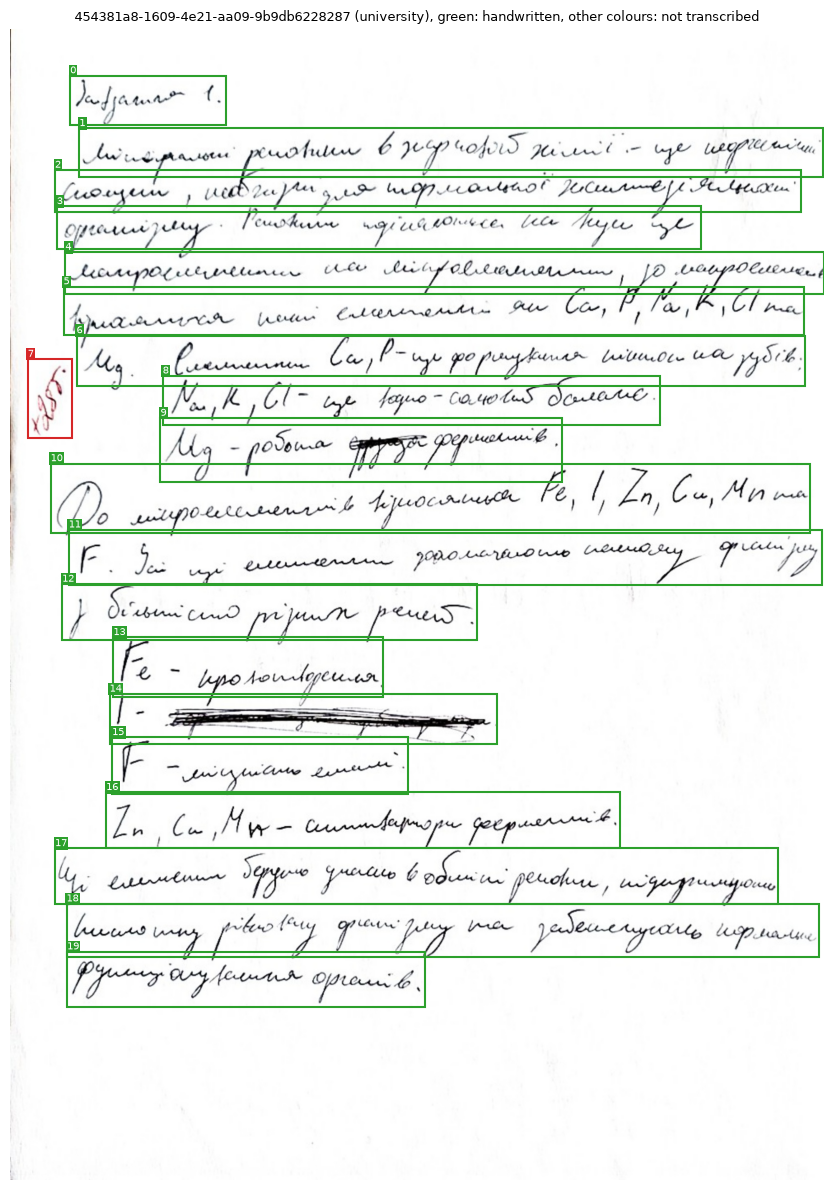

In [4]:
EXAMPLE = None  # set a page_id to override the automatic choice

pages['page_CER'] = pages.char_errors / pages.chars
other_types = {Path(p['file_name']).stem for p in val if any(r['type'] != 'handwritten' for r in regions[p['file_name']])}
pool = pages[pages.page_id.isin(other_types) & (pages.source == 'university') & pages.ref_lines.between(8, 25)]
page_id = EXAMPLE or pool.loc[(pool.page_CER - pool.page_CER.median()).abs().idxmin(), 'page_id']
page = next(p for p in val if Path(p['file_name']).stem == page_id)
found = pd.DataFrame(regions[page['file_name']])
found['text'] = found.text.fillna('not transcribed')
found['score'] = found.score.round(2)
found.index.name = 'order'

colors = {'handwritten': 'tab:green', 'printed': 'tab:blue'}
fig, ax = plt.subplots(figsize=(9, 12))
with Image.open(snapshot() / 'train' / page['file_name']) as image:
    ax.imshow(image.convert('RGB'))
for i, r in enumerate(regions[page['file_name']]):
    x1, y1, x2, y2 = r['box']
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1.5, ec=colors.get(r['type'], 'tab:red')))
    ax.text(x1, y1, str(i), color='white', fontsize=7, va='bottom', bbox=dict(fc=colors.get(r['type'], 'tab:red'), pad=1, lw=0))
ax.set_title(f'{page_id} ({page["source"]}), green: handwritten, other colours: not transcribed', fontsize=9)
ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'page_example.png', dpi=110)
found[['type', 'score', 'text']]

In [5]:
row = pages[pages.page_id == page_id].iloc[0]
print(f'page CER {row.page_CER:.3f} ({row.char_errors} errors / {row.chars} characters)\n')
print('Reference:\n' + row.reference + '\n\nPredicted:\n' + row.prediction)

page CER 0.341 (233 errors / 683 characters)

Reference:
Завдання 1. Мінеральні речовини в харчовій хімії - це неорганічні сполуки, необхідні для нормальної життєдіяльності організму. Речовини поділяються на групи це макроелементи та мікроелементи, до макроелементів приносяться такі елементи як Ca, P, Na, K, Cl та Mg. Елементи Ca, P - це формування кісток та зубів; Na, K, Cl - це водно-сольовий баланс. До мікроелементів відносяться Fe, I, Zn, Cu, Mn та F. Усі ці елементи допомагають нашому організму і більшістю різних речей. Fe - кровотворения. F - міцність емалі. Zn, Cu, Mn - активатори ферментів. Ці елементи беруть участь в обміні речовин, підтримують кислотну рівновагу організму та забезпечують нормальне функціонування органів.

Predicted:
Забдання 1. Міслорамні ромовини в харчовій німії - ще нефектічні сполуши, неовизмі для тормальної житеріяльості організму. Половили подінаються на пусе це Матрослементи на мікремамяти, до матроскала Приамання ники смежені як Са, P, Рa, R1 та Mg. С

## Save

In [6]:
(RESULTS_DIR / 'page_rf-small-refined_metrics.json').write_text(json.dumps(dict(
    detector=str(DETECTOR_DIR.relative_to(ROOT)), model=str(MODEL_DIR.relative_to(ROOT)), decoding=DECODING,
    score_threshold=THRESHOLD, results=table.reset_index(names='source').to_dict('records')), indent=2), encoding='utf-8')
pages.to_csv(RESULTS_DIR / 'page_rf-small-refined_predictions.csv', index=False)